In [1]:
import pandas as pd

df = pd.read_csv("BlinKIT Grocery Data.csv")
df.head()

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.025896,165.0210,5.0
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.042278,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,55.1614,5.0


In [2]:
df.columns

Index(['Item Fat Content', 'Item Identifier', 'Item Type',
       'Outlet Establishment Year', 'Outlet Identifier',
       'Outlet Location Type', 'Outlet Size', 'Outlet Type', 'Item Visibility',
       'Sales', 'Rating'],
      dtype='str')

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item Fat Content           8523 non-null   str    
 1   Item Identifier            8523 non-null   str    
 2   Item Type                  8523 non-null   str    
 3   Outlet Establishment Year  8523 non-null   int64  
 4   Outlet Identifier          8523 non-null   str    
 5   Outlet Location Type       8523 non-null   str    
 6   Outlet Size                8523 non-null   str    
 7   Outlet Type                8523 non-null   str    
 8   Item Visibility            8523 non-null   float64
 9   Sales                      8523 non-null   float64
 10  Rating                     8523 non-null   float64
dtypes: float64(3), int64(1), str(7)
memory usage: 1.2 MB


In [4]:
df.describe()

,Outlet Establishment Year,Item Visibility,Sales,Rating
count,8523.000000,8523.000000,8523.000000,8523.000000
mean,2016.450546,0.066132,140.992783,3.965857
std,3.189396,0.051598,62.275067,0.605651
min,2011.000000,0.000000,31.290000,1.000000
25%,2014.000000,0.026989,93.826500,4.000000
50%,2016.000000,0.053931,143.012800,4.000000
75%,2018.000000,0.094585,185.643700,4.200000
max,2022.000000,0.328391,266.888400,5.000000


Index(['Outlet Establishment Year', 'Item Visibility', 'Sales', 'Rating'],
      dtype='str')


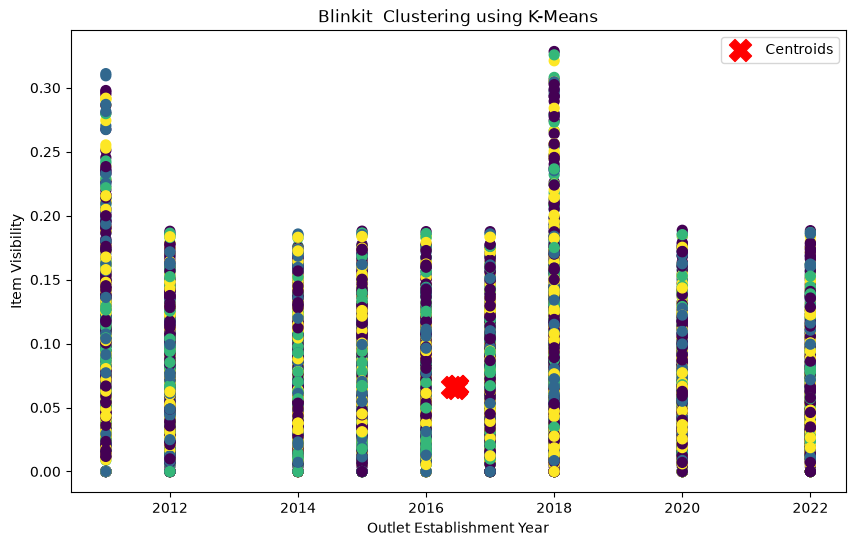

In [5]:
import pandas as pd
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("BlinKIT Grocery Data.csv")

# Select only numerical columns
X = df.select_dtypes(include=['int64', 'float64'])

print(X.columns)

# Remove missing values
X = X.dropna()

# K-Means
kmeans = KMeans(n_clusters=4, random_state=42)
df_cluster = X.copy()
df_cluster["Cluster"] = kmeans.fit_predict(X)

# Plot using first two numeric columns
plt.figure(figsize=(10,6))

plt.scatter(
    df_cluster.iloc[:,0],
    df_cluster.iloc[:,1],
    c=df_cluster["Cluster"],
    cmap="viridis",
    s=50
)

plt.scatter(
    kmeans.cluster_centers_[:,0],
    kmeans.cluster_centers_[:,1],
    c="red",
    marker="X",
    s=250,
    label="Centroids"
)

plt.xlabel(X.columns[0])
plt.ylabel(X.columns[1])
plt.title("Blinkit  Clustering using K-Means")
plt.legend()

plt.show()

In [6]:
X = df[['Item Visibility', 'Sales', 'Rating', 'Outlet Establishment Year']]

X = X.dropna()

In [7]:
X.head()

,Item Visibility,Sales,Rating,Outlet Establishment Year
0,0.100014,145.4786,5.0,2012
1,0.008596,115.3492,5.0,2022
2,0.025896,165.0210,5.0,2016
3,0.042278,126.5046,5.0,2014
4,0.033970,55.1614,5.0,2015


In [8]:
X.shape

(8523, 4)

In [9]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=42)
kmeans.fit(X)

X['Cluster'] = kmeans.labels_

X.head()

,Item Visibility,Sales,Rating,Outlet Establishment Year,Cluster
0,0.100014,145.4786,5.0,2012,0
1,0.008596,115.3492,5.0,2022,1
2,0.025896,165.0210,5.0,2016,0
3,0.042278,126.5046,5.0,2014,0
4,0.033970,55.1614,5.0,2015,1


In [12]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# Select features
features = ['Item Visibility', 'Sales', 'Rating', 'Outlet Establishment Year']

X = df[features].dropna().copy()

# Scale the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply K-Means
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)

# Store cluster labels
X['Cluster'] = kmeans.fit_predict(X_scaled)

print("Clustering completed successfully!")
print(X.head())

Clustering completed successfully!
   Item Visibility     Sales  Rating  Outlet Establishment Year  Cluster
0         0.100014  145.4786     5.0                       2012        1
1         0.008596  115.3492     5.0                       2022        0
2         0.025896  165.0210     5.0                       2016        3
3         0.042278  126.5046     5.0                       2014        2
4         0.033970   55.1614     5.0                       2015        2


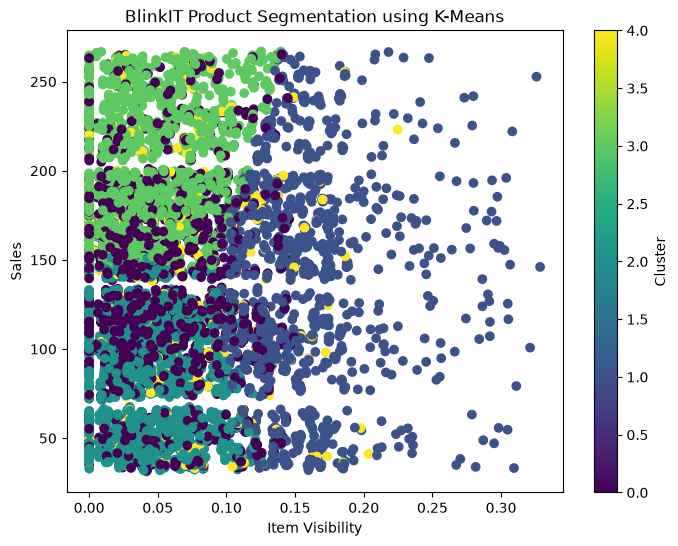

In [13]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X['Item Visibility'],
    X['Sales'],
    c=X['Cluster'],
    cmap='viridis'
)

plt.xlabel("Item Visibility")
plt.ylabel("Sales")
plt.title("BlinkIT Product Segmentation using K-Means")

plt.colorbar(label="Cluster")
plt.show()

In [14]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=42)
X['Cluster'] = kmeans.fit_predict(X)

X.head()

,Item Visibility,Sales,Rating,Outlet Establishment Year,Cluster
0,0.100014,145.4786,5.0,2012,0
1,0.008596,115.3492,5.0,2022,1
2,0.025896,165.0210,5.0,2016,0
3,0.042278,126.5046,5.0,2014,0
4,0.033970,55.1614,5.0,2015,1


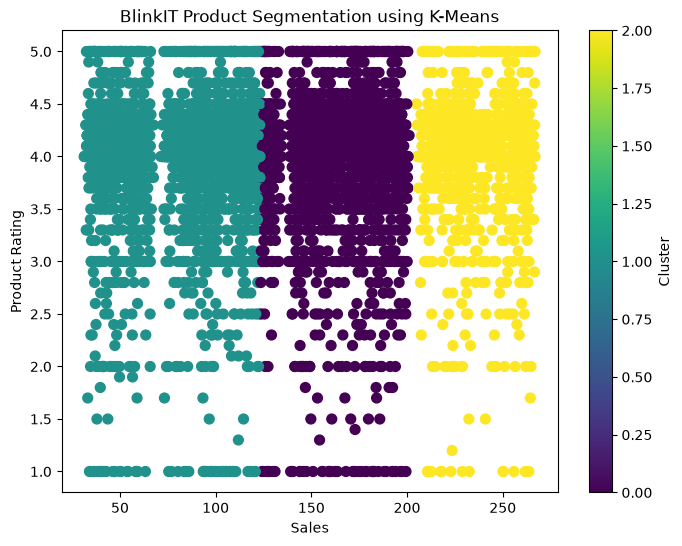

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.scatter(
    X['Sales'],
    X['Rating'],
    c=X['Cluster'],
    cmap='viridis',
    s=50
)

plt.xlabel("Sales")
plt.ylabel("Product Rating")
plt.title("BlinkIT Product Segmentation using K-Means")

plt.colorbar(label="Cluster")
plt.show()

In [16]:
from sklearn.cluster import KMeans

# Create K-Means model
kmeans = KMeans(n_clusters=3, random_state=42)

# Fit model and predict clusters
X['Cluster'] = kmeans.fit_predict(X)

# Check first 5 rows
X.head()

,Item Visibility,Sales,Rating,Outlet Establishment Year,Cluster
0,0.100014,145.4786,5.0,2012,0
1,0.008596,115.3492,5.0,2022,1
2,0.025896,165.0210,5.0,2016,0
3,0.042278,126.5046,5.0,2014,0
4,0.033970,55.1614,5.0,2015,1


In [19]:
# Select required columns
columns = ['Item Visibility', 'Sales', 'Rating']

# Remove rows with missing values
df_clean = df.dropna(subset=columns).copy()

# Features
X = df_clean[columns]

# KMeans
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

df_clean['Cluster'] = kmeans.fit_predict(X)

# Display result
df_clean[['Item Identifier', 'Item Type', 'Sales', 'Rating', 'Cluster']].head()

,Item Identifier,Item Type,Sales,Rating,Cluster
0,FDX32,Fruits and Vegetables,145.4786,5.0,0
1,NCB42,Health and Hygiene,115.3492,5.0,1
2,FDR28,Frozen Foods,165.0210,5.0,0
3,FDL50,Canned,126.5046,5.0,0
4,DRI25,Soft Drinks,55.1614,5.0,1


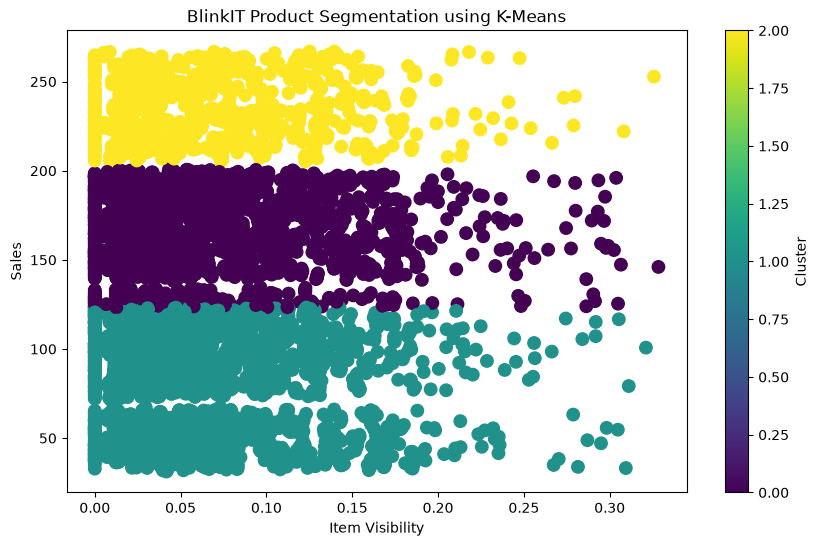

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

plt.scatter(
    df_clean['Item Visibility'],
    df_clean['Sales'],
    c=df_clean['Cluster'],
    cmap='viridis',
    s=80
)

plt.xlabel("Item Visibility")
plt.ylabel("Sales")
plt.title("BlinkIT Product Segmentation using K-Means")

plt.colorbar(label="Cluster")
plt.show()

In [21]:
print(df_clean['Cluster'].value_counts())

Cluster
1    3695
0    3399
2    1429
Name: count, dtype: int64


In [22]:
df_clean.groupby('Cluster')[
    ['Item Visibility', 'Sales', 'Rating']
].mean().round(2)

,Item Visibility,Sales,Rating
Cluster,,,
0,0.07,164.71,3.97
1,0.07,81.84,3.96
2,0.07,237.54,3.97


In [5]:
print('df' in globals())

False
